<a href="https://colab.research.google.com/github/jannatulferdus182003/MLLab/blob/main/Istanbul_Water_Consumption_Prediction.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Istanbul Water Consumption Prediction

**Project:** Daily, Weekly, Monthly and Yearly Water Consumption Forecasting  
**Dataset:** Istanbul Barrage Intake and Consumption  
**Target column:** `Total_Consumption`  
**Algorithms:** Linear Regression, Random Forest Regressor and Gradient Boosting Regressor

## Project objective
This notebook uses historical Istanbul water-consumption and reservoir-intake records to predict the total consumption for the next 1, 7, 30 and 365 days.

**Important:** Weekly, monthly and yearly targets mean the *total consumption over the next 7, 30 and 365 days*, starting after the forecast date. They are rolling periods, not calendar weeks/months/years.

Run the code cells from top to bottom. Read each short explanation before running its cell.

## Step 1 — Import libraries

We use pandas and NumPy to prepare the data, Matplotlib to create graphs, and scikit-learn to train and evaluate the regression models.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from google.colab import files

from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor
from sklearn.ensemble import GradientBoostingRegressor
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

pd.set_option('display.max_columns', 50)
pd.set_option('display.float_format', lambda x: f'{x:,.2f}')

## Step 2 — Upload and read the CSV file

Upload `Istanbul_BarrageIntakeandConsumption.csv` from your computer. The file name below must match the uploaded file name.

In [2]:
uploaded = files.upload()

file_name = 'Istanbul_BarrageIntakeandConsumption.csv'
df = pd.read_csv(file_name)

print('Dataset loaded successfully.')
print('Shape:', df.shape)
display(df.head())

Saving Istanbul_BarrageIntakeandConsumption.csv to Istanbul_BarrageIntakeandConsumption.csv
Dataset loaded successfully.
Shape: (4797, 12)


,Date,Omerli,Darlik,Elmali,Terkos,B.Cekmece,Sazlidere,Alibey,Kazandere,Pabucdere,Istırancalar,Total_Consumption
0,1/1/2011,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,2096199
1,1/2/2011,0.00,0.00,0.00,0.42,1.37,0.87,0.20,2.26,1.89,1.39,2214668
2,1/3/2011,8.08,10.01,11.64,18.82,9.64,14.72,13.50,8.20,10.37,16.47,2092441
3,1/4/2011,2.78,8.48,7.09,3.42,0.83,4.31,4.30,1.44,1.60,3.99,2096199
4,1/5/2011,0.00,0.78,0.00,0.42,0.00,0.00,0.56,1.15,1.11,0.80,2214668


## Step 3 — Understand the dataset

This cell displays the column names, data types, number of records and statistical summary. It helps us understand what information is available before training.

In [3]:
print('Rows and columns:', df.shape)
print('\nColumn names:')
print(df.columns.tolist())

print('\nData types:')
print(df.dtypes)

print('\nDataset information:')
df.info()

print('\nNumerical summary:')
display(df.describe())

Rows and columns: (4797, 12)

Column names:
['Date', 'Omerli', 'Darlik', 'Elmali', 'Terkos', 'B.Cekmece', 'Sazlidere', 'Alibey', 'Kazandere', 'Pabucdere', 'Istırancalar', 'Total_Consumption']

Data types:
Date                  object
Omerli               float64
Darlik               float64
Elmali               float64
Terkos               float64
B.Cekmece            float64
Sazlidere            float64
Alibey               float64
Kazandere            float64
Pabucdere            float64
Istırancalar         float64
Total_Consumption      int64
dtype: object

Dataset information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 4797 entries, 0 to 4796
Data columns (total 12 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   Date               4797 non-null   object 
 1   Omerli             4797 non-null   float64
 2   Darlik             4797 non-null   float64
 3   Elmali             4797 non-null   float64
 4   Terkos     

,Omerli,Darlik,Elmali,Terkos,B.Cekmece,Sazlidere,Alibey,Kazandere,Pabucdere,Istırancalar,Total_Consumption
count,"4,797.00","4,797.00","4,797.00","4,797.00","4,797.00","4,797.00","4,797.00","4,797.00","4,797.00","4,797.00","4,797.00"
mean,2.07,2.27,1.89,2.41,1.68,1.82,2.02,2.60,2.45,2.43,"2,737,182.16"
std,5.93,6.11,5.60,7.10,5.34,6.26,6.10,8.74,8.10,7.71,"300,378.86"
min,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,"1,949,139.00"
25%,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,"2,532,130.00"
50%,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,"2,753,570.00"
75%,0.93,1.20,0.70,1.11,0.40,0.50,0.70,0.55,0.43,1.00,"2,941,013.00"
max,123.53,82.69,95.47,131.28,95.59,178.25,119.00,170.20,171.08,172.00,"3,568,056.00"


## Step 4 — Check missing values, duplicate rows and zero reservoir values

Missing values and duplicate rows are checked separately. Reservoir columns contain many zero values in this dataset. We do **not** automatically replace those zeros because they may represent actual recorded values; their meaning should be checked against the dataset documentation.

In [4]:
print('Missing values in each column:')
display(df.isnull().sum())

print('Total missing values:', df.isnull().sum().sum())
print('Duplicate rows:', df.duplicated().sum())

reservoir_columns = [
    'Omerli', 'Darlik', 'Elmali', 'Terkos', 'B.Cekmece',
    'Sazlidere', 'Alibey', 'Kazandere', 'Pabucdere', 'Istırancalar'
]

print('\nShare of zero values in each reservoir column:')
display((df[reservoir_columns] == 0).mean().sort_values(ascending=False))

Missing values in each column:


,0
Date,0
Omerli,0
Darlik,0
Elmali,0
Terkos,0
B.Cekmece,0
Sazlidere,0
Alibey,0
Kazandere,0
Pabucdere,0


Total missing values: 0
Duplicate rows: 0

Share of zero values in each reservoir column:


,0
Pabucdere,0.73
B.Cekmece,0.72
Kazandere,0.72
Sazlidere,0.72
Omerli,0.70
Alibey,0.70
Istırancalar,0.69
Elmali,0.69
Terkos,0.68
Darlik,0.67


## Step 5 — Convert dates and sort records

The date column is converted to a datetime format. The records are then sorted from the earliest date to the latest date, which is essential for time-series forecasting.

In [5]:
df['Date'] = pd.to_datetime(df['Date'], format='%m/%d/%Y', errors='raise')
df = df.sort_values('Date').reset_index(drop=True)

print('First date:', df['Date'].min())
print('Last date:', df['Date'].max())
display(df.head())

First date: 2011-01-01 00:00:00
Last date: 2024-02-18 00:00:00


,Date,Omerli,Darlik,Elmali,Terkos,B.Cekmece,Sazlidere,Alibey,Kazandere,Pabucdere,Istırancalar,Total_Consumption
0,2011-01-01,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,2096199
1,2011-01-02,0.00,0.00,0.00,0.42,1.37,0.87,0.20,2.26,1.89,1.39,2214668
2,2011-01-03,8.08,10.01,11.64,18.82,9.64,14.72,13.50,8.20,10.37,16.47,2092441
3,2011-01-04,2.78,8.48,7.09,3.42,0.83,4.31,4.30,1.44,1.60,3.99,2096199
4,2011-01-05,0.00,0.78,0.00,0.42,0.00,0.00,0.56,1.15,1.11,0.80,2214668


## Step 6 — Check whether daily dates are continuous

This check identifies missing calendar dates. A missing date is different from a missing cell value. We report any missing dates rather than inventing consumption values for them.

In [6]:
expected_dates = pd.date_range(
    start=df['Date'].min(),
    end=df['Date'].max(),
    freq='D'
)

missing_dates = expected_dates.difference(df['Date'])

print('Expected daily records:', len(expected_dates))
print('Actual records:', len(df))
print('Missing dates:', len(missing_dates))

if len(missing_dates) > 0:
    print(missing_dates[:20])
else:
    print('There are no missing calendar dates.')

Expected daily records: 4797
Actual records: 4797
Missing dates: 0
There are no missing calendar dates.


## Step 7 — Exploratory data analysis (EDA)

The following graphs help us inspect historical consumption, monthly patterns and average intake by reservoir. These are descriptive analyses; they do not train a model.

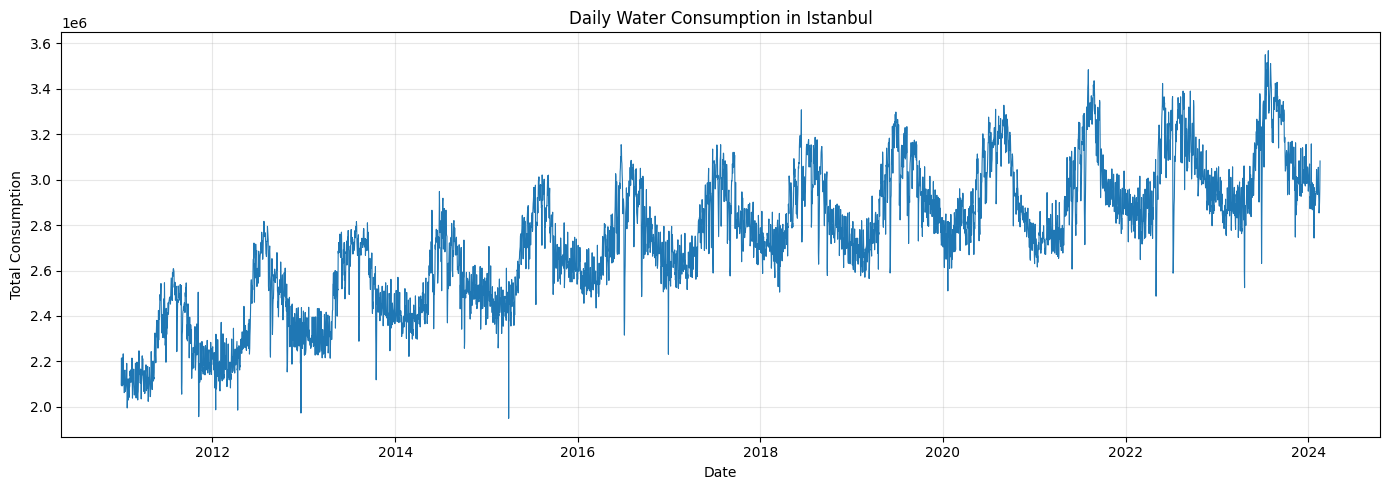

In [7]:
plt.figure(figsize=(14, 5))
plt.plot(df['Date'], df['Total_Consumption'], linewidth=0.8)
plt.title('Daily Water Consumption in Istanbul')
plt.xlabel('Date')
plt.ylabel('Total Consumption')
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

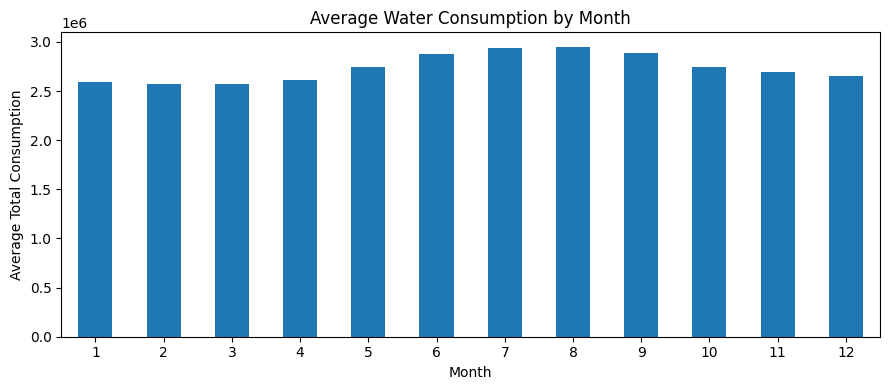

In [8]:
monthly_average = df.groupby(df['Date'].dt.month)['Total_Consumption'].mean()

plt.figure(figsize=(9, 4))
monthly_average.plot(kind='bar')
plt.title('Average Water Consumption by Month')
plt.xlabel('Month')
plt.ylabel('Average Total Consumption')
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

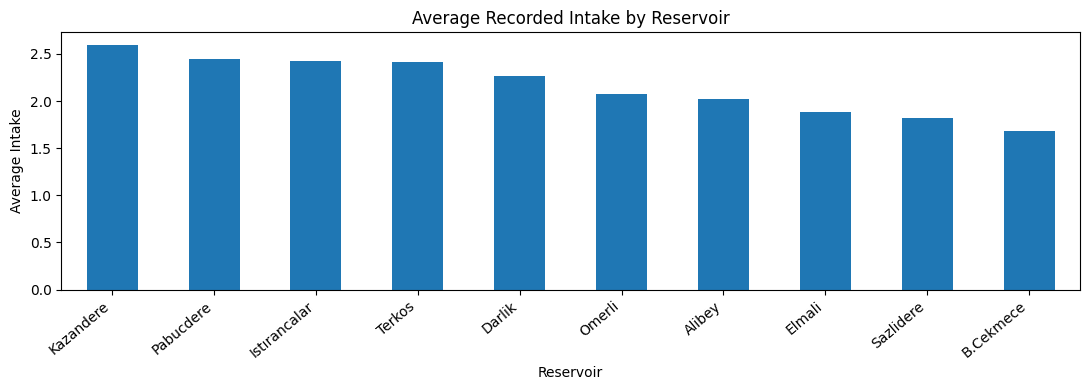

In [9]:
reservoir_average = df[reservoir_columns].mean().sort_values(ascending=False)

plt.figure(figsize=(11, 4))
reservoir_average.plot(kind='bar')
plt.title('Average Recorded Intake by Reservoir')
plt.xlabel('Reservoir')
plt.ylabel('Average Intake')
plt.xticks(rotation=40, ha='right')
plt.tight_layout()
plt.show()

## Step 8 — Calculate mean, median and mode

These descriptive statistics summarize the numerical columns. The mode shown is the first mode returned for each column; a column can have more than one mode.

In [10]:
numeric_columns = df.select_dtypes(include=np.number).columns

statistics = pd.DataFrame({
    'Mean': df[numeric_columns].mean(),
    'Median': df[numeric_columns].median(),
    'Mode': df[numeric_columns].mode().iloc[0]
})

display(statistics)

,Mean,Median,Mode
Omerli,2.07,0.00,0.00
Darlik,2.27,0.00,0.00
Elmali,1.89,0.00,0.00
Terkos,2.41,0.00,0.00
B.Cekmece,1.68,0.00,0.00
Sazlidere,1.82,0.00,0.00
Alibey,2.02,0.00,0.00
Kazandere,2.60,0.00,0.00
Pabucdere,2.45,0.00,0.00
Istırancalar,2.43,0.00,0.00


## Step 9 — Create input features (feature engineering)

The model needs information that would be available on the forecast date. We create calendar features, current recorded consumption and reservoir intake, historical lag values, rolling averages, and seasonal cycle features.

`shift(1)` is used for lag and rolling features so that their values only use earlier records. Current-day consumption and intake are included because this notebook assumes the forecast is made after that day's records are available.

In [11]:
data = df.copy()

# Calendar and trend features
data['Day'] = data['Date'].dt.day
data['Month'] = data['Date'].dt.month
data['DayOfWeek'] = data['Date'].dt.dayofweek
data['DayOfYear'] = data['Date'].dt.dayofyear
data['Trend_Day'] = (data['Date'] - data['Date'].min()).dt.days

# Cyclical calendar features
data['Year_Sin'] = np.sin(2 * np.pi * data['DayOfYear'] / 365.25)
data['Year_Cos'] = np.cos(2 * np.pi * data['DayOfYear'] / 365.25)
data['Week_Sin'] = np.sin(2 * np.pi * data['DayOfWeek'] / 7)
data['Week_Cos'] = np.cos(2 * np.pi * data['DayOfWeek'] / 7)

# Consumption history
for lag in [1, 7, 14, 30, 365]:
    data[f'Consumption_Lag_{lag}'] = data['Total_Consumption'].shift(lag)

for window in [7, 30]:
    data[f'Consumption_Rolling_{window}'] = (
        data['Total_Consumption'].shift(1).rolling(window).mean()
    )

# Reservoir history
for col in reservoir_columns:
    data[f'{col}_Lag_1'] = data[col].shift(1)
    data[f'{col}_Rolling_7'] = data[col].shift(1).rolling(7).mean()

print('Feature engineering completed.')
display(data.head(10))

Feature engineering completed.


,Date,Omerli,Darlik,Elmali,Terkos,B.Cekmece,Sazlidere,Alibey,Kazandere,Pabucdere,Istırancalar,Total_Consumption,Day,Month,DayOfWeek,DayOfYear,Trend_Day,Year_Sin,Year_Cos,Week_Sin,Week_Cos,Consumption_Lag_1,Consumption_Lag_7,Consumption_Lag_14,Consumption_Lag_30,Consumption_Lag_365,Consumption_Rolling_7,Consumption_Rolling_30,Omerli_Lag_1,Omerli_Rolling_7,Darlik_Lag_1,Darlik_Rolling_7,Elmali_Lag_1,Elmali_Rolling_7,Terkos_Lag_1,Terkos_Rolling_7,B.Cekmece_Lag_1,B.Cekmece_Rolling_7,Sazlidere_Lag_1,Sazlidere_Rolling_7,Alibey_Lag_1,Alibey_Rolling_7,Kazandere_Lag_1,Kazandere_Rolling_7,Pabucdere_Lag_1,Pabucdere_Rolling_7,Istırancalar_Lag_1,Istırancalar_Rolling_7
0,2011-01-01,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,2096199,1,1,5,1,0,0.02,1.00,-0.97,-0.22,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,2011-01-02,0.00,0.00,0.00,0.42,1.37,0.87,0.20,2.26,1.89,1.39,2214668,2,1,6,2,1,0.03,1.00,-0.78,0.62,"2,096,199.00",NaN,NaN,NaN,NaN,NaN,NaN,0.00,NaN,0.00,NaN,0.00,NaN,0.00,NaN,0.00,NaN,0.00,NaN,0.00,NaN,0.00,NaN,0.00,NaN,0.00,NaN
2,2011-01-03,8.08,10.01,11.64,18.82,9.64,14.72,13.50,8.20,10.37,16.47,2092441,3,1,0,3,2,0.05,1.00,0.00,1.00,"2,214,668.00",NaN,NaN,NaN,NaN,NaN,NaN,0.00,NaN,0.00,NaN,0.00,NaN,0.42,NaN,1.37,NaN,0.87,NaN,0.20,NaN,2.26,NaN,1.89,NaN,1.39,NaN
3,2011-01-04,2.78,8.48,7.09,3.42,0.83,4.31,4.30,1.44,1.60,3.99,2096199,4,1,1,4,3,0.07,1.00,0.78,0.62,"2,092,441.00",NaN,NaN,NaN,NaN,NaN,NaN,8.08,NaN,10.01,NaN,11.64,NaN,18.82,NaN,9.64,NaN,14.72,NaN,13.50,NaN,8.20,NaN,10.37,NaN,16.47,NaN
4,2011-01-05,0.00,0.78,0.00,0.42,0.00,0.00,0.56,1.15,1.11,0.80,2214668,5,1,2,5,4,0.09,1.00,0.97,-0.22,"2,096,199.00",NaN,NaN,NaN,NaN,NaN,NaN,2.78,NaN,8.48,NaN,7.09,NaN,3.42,NaN,0.83,NaN,4.31,NaN,4.30,NaN,1.44,NaN,1.60,NaN,3.99,NaN
5,2011-01-06,0.00,3.05,0.70,9.11,0.00,0.64,3.37,1.25,1.60,0.74,2092441,6,1,3,6,5,0.10,0.99,0.43,-0.90,"2,214,668.00",NaN,NaN,NaN,NaN,NaN,NaN,0.00,NaN,0.78,NaN,0.00,NaN,0.42,NaN,0.00,NaN,0.00,NaN,0.56,NaN,1.15,NaN,1.11,NaN,0.80,NaN
6,2011-01-07,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,2096199,7,1,4,7,6,0.12,0.99,-0.43,-0.90,"2,092,441.00",NaN,NaN,NaN,NaN,NaN,NaN,0.00,NaN,3.05,NaN,0.70,NaN,9.11,NaN,0.00,NaN,0.64,NaN,3.37,NaN,1.25,NaN,1.60,NaN,0.74,NaN
7,2011-01-08,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,2170233,8,1,5,8,7,0.14,0.99,-0.97,-0.22,"2,096,199.00","2,096,199.00",NaN,NaN,NaN,"2,128,973.57",NaN,0.00,1.55,0.00,3.19,0.00,2.78,0.00,4.60,0.00,1.69,0.00,2.93,0.00,3.13,0.00,2.04,0.00,2.37,0.00,3.34
8,2011-01-09,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,2233155,9,1,6,9,8,0.15,0.99,-0.78,0.62,"2,170,233.00","2,214,668.00",NaN,NaN,NaN,"2,139,549.86",NaN,0.00,1.55,0.00,3.19,0.00,2.78,0.00,4.60,0.00,1.69,0.00,2.93,0.00,3.13,0.00,2.04,0.00,2.37,0.00,3.34
9,2011-01-10,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,2145587,10,1,0,10,9,0.17,0.99,0.00,1.00,"2,233,155.00","2,092,441.00",NaN,NaN,NaN,"2,142,190.86",NaN,0.00,1.55,0.00,3.19,0.00,2.78,0.00,4.54,0.00,1.50,0.00,2.81,0.00,3.10,0.00,1.72,0.00,2.10,0.00,3.14


## Step 10 — Select the input features (X)

We include the current day's consumption and reservoir readings, plus the engineered historical features. We do not use future reservoir readings because those values would not be known when making a forecast.

In [12]:
features = [
    'Day', 'Month', 'DayOfWeek', 'DayOfYear',
    'Year_Sin', 'Year_Cos', 'Week_Sin', 'Week_Cos',
    'Trend_Day', 'Total_Consumption'
]

for lag in [1, 7, 14, 30, 365]:
    features.append(f'Consumption_Lag_{lag}')

for window in [7, 30]:
    features.append(f'Consumption_Rolling_{window}')

for col in reservoir_columns:
    features.append(f'{col}_Lag_1')
    features.append(f'{col}_Rolling_7')

print('Number of input features:', len(features))
print(features)

Number of input features: 37
['Day', 'Month', 'DayOfWeek', 'DayOfYear', 'Year_Sin', 'Year_Cos', 'Week_Sin', 'Week_Cos', 'Trend_Day', 'Total_Consumption', 'Consumption_Lag_1', 'Consumption_Lag_7', 'Consumption_Lag_14', 'Consumption_Lag_30', 'Consumption_Lag_365', 'Consumption_Rolling_7', 'Consumption_Rolling_30', 'Omerli_Lag_1', 'Omerli_Rolling_7', 'Darlik_Lag_1', 'Darlik_Rolling_7', 'Elmali_Lag_1', 'Elmali_Rolling_7', 'Terkos_Lag_1', 'Terkos_Rolling_7', 'B.Cekmece_Lag_1', 'B.Cekmece_Rolling_7', 'Sazlidere_Lag_1', 'Sazlidere_Rolling_7', 'Alibey_Lag_1', 'Alibey_Rolling_7', 'Kazandere_Lag_1', 'Kazandere_Rolling_7', 'Pabucdere_Lag_1', 'Pabucdere_Rolling_7', 'Istırancalar_Lag_1', 'Istırancalar_Rolling_7']


## Step 11 — Create four forecasting targets

For each date, the targets represent consumption *after* that date:
- Daily: next 1 day
- Weekly: sum of next 7 days
- Monthly: sum of next 30 days
- Yearly: sum of next 365 days

The targets are shifted so the current date's consumption is not included in the future-period total.

In [13]:
horizons = {
    'Daily': 1,
    'Weekly': 7,
    'Monthly': 30,
    'Yearly': 365
}

for name, days in horizons.items():
    future_values = data['Total_Consumption'].shift(-1)
    data[f'Target_{name}'] = (
        future_values
        .rolling(window=days)
        .sum()
        .shift(-(days - 1))
    )

target_columns = [
    'Date', 'Total_Consumption',
    'Target_Daily', 'Target_Weekly',
    'Target_Monthly', 'Target_Yearly'
]

display(data[target_columns].head(10))

,Date,Total_Consumption,Target_Daily,Target_Weekly,Target_Monthly,Target_Yearly
0,2011-01-01,2096199,"2,214,668.00","14,976,849.00","63,332,102.00","824,167,007.00"
1,2011-01-02,2214668,"2,092,441.00","14,995,336.00","63,158,320.00","824,216,681.00"
2,2011-01-03,2092441,"2,096,199.00","15,048,482.00","63,190,712.00","824,339,215.00"
3,2011-01-04,2096199,"2,214,668.00","15,052,091.00","63,180,189.00","824,451,569.00"
4,2011-01-05,2214668,"2,092,441.00","14,947,956.00","63,056,989.00","824,458,833.00"
5,2011-01-06,2092441,"2,096,199.00","14,917,696.00","63,120,616.00","824,531,435.00"
6,2011-01-07,2096199,"2,170,233.00","14,887,341.00","63,161,548.00","824,597,148.00"
7,2011-01-08,2170233,"2,233,155.00","14,874,199.00","63,153,609.00","824,665,707.00"
8,2011-01-09,2233155,"2,145,587.00","14,802,544.00","63,032,242.00","824,580,606.00"
9,2011-01-10,2145587,"2,099,808.00","14,741,483.00","62,994,410.00","824,563,203.00"


## Step 12 — Define the three regression algorithms

We compare Linear Regression, Random Forest Regressor and Gradient Boosting Regressor. XGBoost is not used. Linear Regression is scaled with `StandardScaler`; the tree-based models do not require feature scaling.

In [14]:
def create_models():
    return {
        'Linear Regression': make_pipeline(
            StandardScaler(),
            LinearRegression()
        ),
        'Random Forest': RandomForestRegressor(
            n_estimators=200,
            max_depth=15,
            min_samples_leaf=2,
            random_state=42,
            n_jobs=-1
        ),
        'Gradient Boosting': GradientBoostingRegressor(
            n_estimators=200,
            learning_rate=0.05,
            max_depth=2,
            random_state=42
        )
    }

## Step 13 — Train, validate and test each model

For each forecast horizon, records are kept in chronological order:
- First 70%: training
- Next 15%: validation
- Last 15%: testing

We leave a gap equal to the forecast horizon at the split boundaries. This reduces overlap between future-period target windows across the training, validation and test sections.

The best algorithm is selected using the **lowest validation RMSE**. The selected algorithm is then refitted on the training and validation sections and evaluated once on the untouched test section.

In [15]:
results = []
best_models = {}
test_predictions = {}
test_actuals = {}

for name, days in horizons.items():
    target = f'Target_{name}'

    # Keep only rows with all input features and this target available
    model_data = data.dropna(subset=features + [target]).copy().reset_index(drop=True)

    n = len(model_data)
    train_end = int(n * 0.70)
    val_end = int(n * 0.85)

    # Purge boundary rows so target periods do not overlap between splits
    train_data = model_data.iloc[:max(0, train_end - days)]
    val_data = model_data.iloc[train_end:max(train_end, val_end - days)]
    test_data = model_data.iloc[val_end:]

    if min(len(train_data), len(val_data), len(test_data)) == 0:
        raise ValueError(f'Not enough data for {name} horizon.')

    X_train, y_train = train_data[features], train_data[target]
    X_val, y_val = val_data[features], val_data[target]
    X_test, y_test = test_data[features], test_data[target]

    print('\n' + '=' * 55)
    print(name, 'forecast')
    print('Training rows:', len(train_data))
    print('Validation rows:', len(val_data))
    print('Testing rows:', len(test_data))

    validation_rmse = {}

    for model_name, model in create_models().items():
        model.fit(X_train, y_train)
        val_pred = model.predict(X_val)

        val_mae = mean_absolute_error(y_val, val_pred)
        val_rmse = np.sqrt(mean_squared_error(y_val, val_pred))
        val_r2 = r2_score(y_val, val_pred)

        validation_rmse[model_name] = val_rmse

        results.append({
            'Forecast': name,
            'Algorithm': model_name,
            'Validation_MAE': val_mae,
            'Validation_RMSE': val_rmse,
            'Validation_R2': val_r2
        })

        print(f'{model_name}: MAE={val_mae:,.2f}, RMSE={val_rmse:,.2f}, R2={val_r2:.4f}')

    best_name = min(validation_rmse, key=validation_rmse.get)
    print('Selected algorithm:', best_name)

    # Refit the selected algorithm using training + validation data only
    train_validation_data = pd.concat([train_data, val_data])
    final_model = create_models()[best_name]
    final_model.fit(
        train_validation_data[features],
        train_validation_data[target]
    )

    test_pred = final_model.predict(X_test)

    test_mae = mean_absolute_error(y_test, test_pred)
    test_rmse = np.sqrt(mean_squared_error(y_test, test_pred))
    test_r2 = r2_score(y_test, test_pred)

    print('Final test MAE:', round(test_mae, 2))
    print('Final test RMSE:', round(test_rmse, 2))
    print('Final test R2:', round(test_r2, 4))

    best_models[name] = best_name
    test_predictions[name] = pd.Series(test_pred, index=test_data.index)
    test_actuals[name] = y_test.copy()

    results[-3:]  # keep the validation metrics for all algorithms
    results.append({
        'Forecast': name,
        'Algorithm': best_name + ' (Test)',
        'Validation_MAE': np.nan,
        'Validation_RMSE': np.nan,
        'Validation_R2': np.nan,
        'Test_MAE': test_mae,
        'Test_RMSE': test_rmse,
        'Test_R2': test_r2
    })

print('\nTraining and evaluation completed.')


Daily forecast
Training rows: 3100
Validation rows: 664
Testing rows: 665
Linear Regression: MAE=53,089.74, RMSE=71,508.62, R2=0.8576
Random Forest: MAE=67,424.72, RMSE=90,727.51, R2=0.7708
Gradient Boosting: MAE=71,679.72, RMSE=106,545.99, R2=0.6839
Selected algorithm: Linear Regression
Final test MAE: 58851.08
Final test RMSE: 83849.09
Final test R2: 0.7851

Weekly forecast
Training rows: 3090
Validation rows: 657
Testing rows: 664
Linear Regression: MAE=396,617.76, RMSE=497,946.23, R2=0.8404
Random Forest: MAE=530,523.61, RMSE=772,394.47, R2=0.6160
Gradient Boosting: MAE=548,647.02, RMSE=843,636.92, R2=0.5419
Selected algorithm: Linear Regression
Final test MAE: 375089.25
Final test RMSE: 546300.18
Final test R2: 0.7675

Monthly forecast
Training rows: 3051
Validation rows: 630
Testing rows: 661
Linear Regression: MAE=1,958,391.58, RMSE=2,317,483.56, R2=0.7973
Random Forest: MAE=2,285,645.38, RMSE=3,040,126.03, R2=0.6511
Gradient Boosting: MAE=2,534,696.25, RMSE=3,425,739.76, R2=0.

## Step 14 — Compare validation and test results

The first three rows for each horizon show validation scores for the three algorithms. The row marked `(Test)` shows the final test performance of the selected algorithm. Lower MAE/RMSE is better; an R² closer to 1 is generally better.

In [16]:
results_df = pd.DataFrame(results)
display(results_df)

,Forecast,Algorithm,Validation_MAE,Validation_RMSE,Validation_R2,Test_MAE,Test_RMSE,Test_R2
0,Daily,Linear Regression,"53,089.74","71,508.62",0.86,NaN,NaN,NaN
1,Daily,Random Forest,"67,424.72","90,727.51",0.77,NaN,NaN,NaN
2,Daily,Gradient Boosting,"71,679.72","106,545.99",0.68,NaN,NaN,NaN
3,Daily,Linear Regression (Test),NaN,NaN,NaN,"58,851.08","83,849.09",0.79
4,Weekly,Linear Regression,"396,617.76","497,946.23",0.84,NaN,NaN,NaN
5,Weekly,Random Forest,"530,523.61","772,394.47",0.62,NaN,NaN,NaN
6,Weekly,Gradient Boosting,"548,647.02","843,636.92",0.54,NaN,NaN,NaN
7,Weekly,Linear Regression (Test),NaN,NaN,NaN,"375,089.25","546,300.18",0.77
8,Monthly,Linear Regression,"1,958,391.58","2,317,483.56",0.80,NaN,NaN,NaN
9,Monthly,Random Forest,"2,285,645.38","3,040,126.03",0.65,NaN,NaN,NaN


## Step 15 — Plot validation RMSE for each forecast horizon

This graph compares the validation RMSE of the three algorithms. Compare algorithms within the same forecast horizon; total errors across different horizons are not directly comparable because the target periods have different lengths.

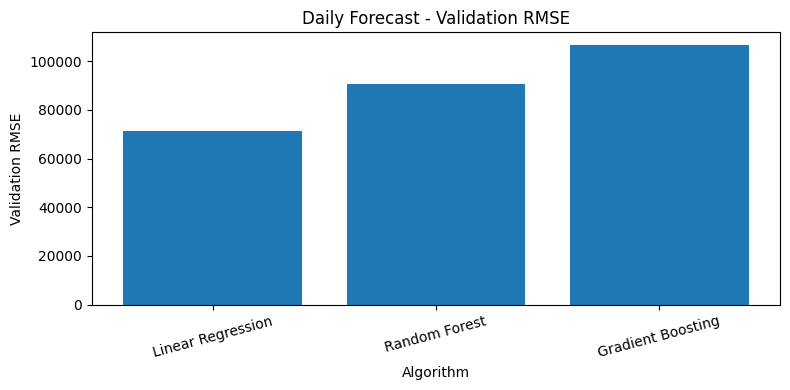

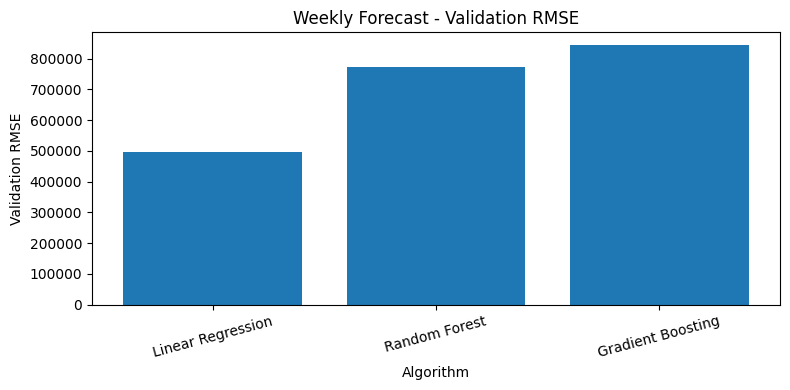

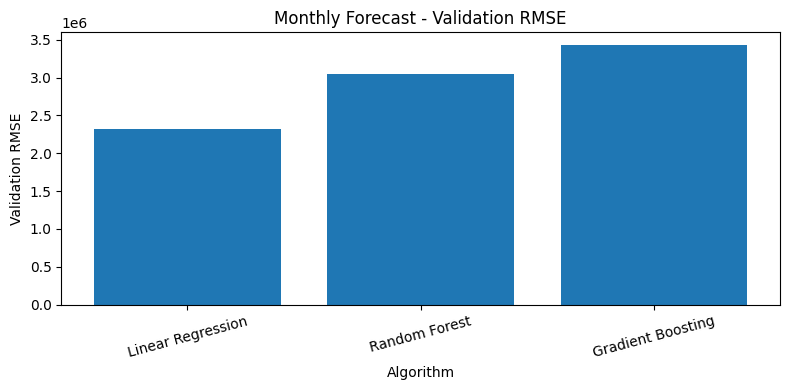

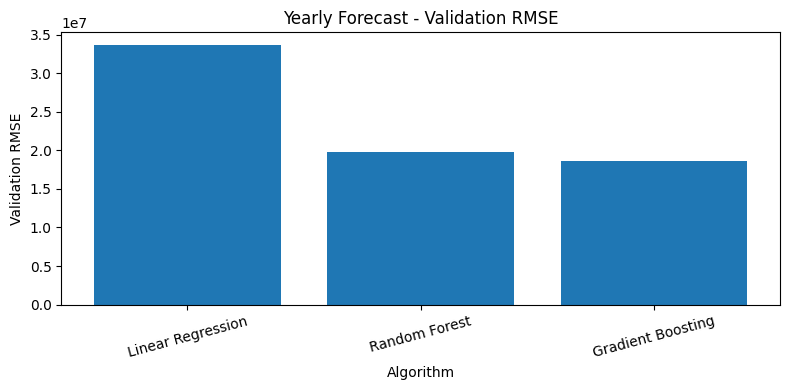

In [17]:
for prediction_name in horizons:
    subset = results_df[
        (results_df['Forecast'] == prediction_name) &
        (~results_df['Algorithm'].str.contains(r'\(Test\)', regex=True))
    ]

    plt.figure(figsize=(8, 4))
    plt.bar(subset['Algorithm'], subset['Validation_RMSE'])
    plt.title(f'{prediction_name} Forecast - Validation RMSE')
    plt.xlabel('Algorithm')
    plt.ylabel('Validation RMSE')
    plt.xticks(rotation=15)
    plt.tight_layout()
    plt.show()

## Step 16 — Refit the selected models using all labeled historical data

After the test scores have been recorded, we refit each selected algorithm on all rows for which its target is known. This creates the final models used for the forecast beyond the last date in the dataset.

This step is for producing the final forecast; the earlier test scores remain the performance estimate.

In [18]:
final_models = {}

for name, days in horizons.items():
    target = f'Target_{name}'
    model_data = data.dropna(subset=features + [target]).copy()

    selected_name = best_models[name]
    final_model = create_models()[selected_name]

    final_model.fit(model_data[features], model_data[target])
    final_models[name] = final_model

    print(f'{name}: final model trained using {selected_name}')

Daily: final model trained using Linear Regression
Weekly: final model trained using Linear Regression
Monthly: final model trained using Linear Regression
Yearly: final model trained using Gradient Boosting


## Step 17 — Predict the next 1, 7, 30 and 365 days

The latest row with complete input features is used as the forecast origin. The prediction starts on the calendar day immediately after the latest dataset date.

The output values are total consumption over each future period, not daily averages.

In [19]:
latest_feature_rows = data.dropna(subset=features)
latest_row = latest_feature_rows.tail(1)
forecast_origin = latest_row['Date'].iloc[0]

predictions = {}

for name, days in horizons.items():
    predicted_total = final_models[name].predict(latest_row[features])[0]
    predictions[name] = predicted_total

    print(f'{name} ({days} day(s))')
    print('Predicted total consumption:', f'{predicted_total:,.2f}')
    print()

print('Forecast origin:', forecast_origin.date())
print('Forecast starts:', (forecast_origin + pd.Timedelta(days=1)).date())

Daily (1 day(s))
Predicted total consumption: 3,014,398.32

Weekly (7 day(s))
Predicted total consumption: 20,820,793.97

Monthly (30 day(s))
Predicted total consumption: 89,101,444.82

Yearly (365 day(s))
Predicted total consumption: 1,117,842,261.31

Forecast origin: 2024-02-18
Forecast starts: 2024-02-19


## Step 18 — Display the final prediction table

The table displays the predicted total consumption and its average per day. The average is calculated by dividing the predicted period total by the number of days.

In [20]:
prediction_table = pd.DataFrame({
    'Period': ['Daily', 'Weekly', 'Monthly', 'Yearly'],
    'Number_of_Days': [1, 7, 30, 365],
    'Predicted_Total_Consumption': [
        predictions['Daily'],
        predictions['Weekly'],
        predictions['Monthly'],
        predictions['Yearly']
    ]
})

prediction_table['Average_Per_Day'] = (
    prediction_table['Predicted_Total_Consumption'] /
    prediction_table['Number_of_Days']
)

display(prediction_table.round(2))

,Period,Number_of_Days,Predicted_Total_Consumption,Average_Per_Day
0,Daily,1,"3,014,398.32","3,014,398.32"
1,Weekly,7,"20,820,793.97","2,974,399.14"
2,Monthly,30,"89,101,444.82","2,970,048.16"
3,Yearly,365,"1,117,842,261.31","3,062,581.54"


## Step 19 — Plot the final forecasts

The first chart compares total consumption for the four forecast periods. Since the periods have different lengths, the second chart compares their average daily consumption, which is more suitable for comparing the forecast levels.

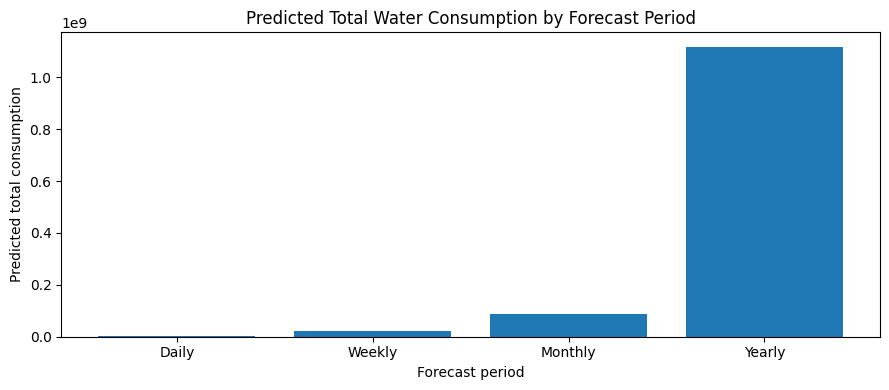

In [21]:
plt.figure(figsize=(9, 4))
plt.bar(
    prediction_table['Period'],
    prediction_table['Predicted_Total_Consumption']
)
plt.title('Predicted Total Water Consumption by Forecast Period')
plt.xlabel('Forecast period')
plt.ylabel('Predicted total consumption')
plt.tight_layout()
plt.show()

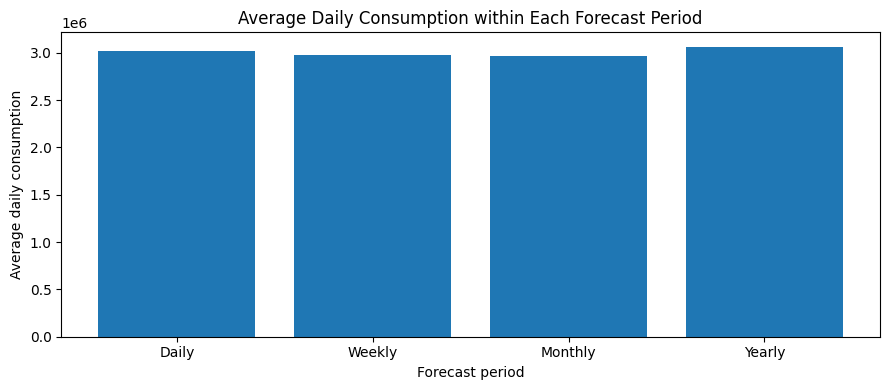

In [22]:
plt.figure(figsize=(9, 4))
plt.bar(
    prediction_table['Period'],
    prediction_table['Average_Per_Day']
)
plt.title('Average Daily Consumption within Each Forecast Period')
plt.xlabel('Forecast period')
plt.ylabel('Average daily consumption')
plt.tight_layout()
plt.show()

## Step 20 — Save the results

This cell saves the prediction table and model comparison results as CSV files, then downloads them from Google Colab.

In [23]:
prediction_table.to_csv('Istanbul_Water_Predictions.csv', index=False)
results_df.to_csv('Istanbul_Model_Comparison.csv', index=False)

files.download('Istanbul_Water_Predictions.csv')
files.download('Istanbul_Model_Comparison.csv')

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

## Final notes and limitations

1. The dataset covers **1 January 2011 to 18 February 2024**. Therefore, the forecast made by this notebook begins after the latest date in that dataset, not from the current date.
2. The unit of `Total_Consumption` is not identified by the CSV columns alone. Confirm the unit from the original data source before labeling the results as litres, cubic metres or another unit.
3. Many reservoir readings are zero. This notebook keeps them unchanged; verify their meaning from the source documentation.
4. Weekly, monthly and yearly values are totals for the next 7, 30 and 365 days. They are not calendar-period totals.
5. Yearly forecasts are more difficult to validate because there are fewer independent one-year periods in the historical dataset. Treat the yearly result cautiously.
6. This notebook uses direct forecasting: one model predicts the total for each horizon from the latest historical feature row. It does not generate a separate prediction for every day inside the future period.
7. A good test score does not guarantee that future conditions will remain the same. Report the evaluation metrics along with the predictions.